# Lesson 7 — Derivatives and Gradients: Which Way to Move a Parameter

[Course plan](../../README.md) · [Previous lesson](lesson-06.ipynb) · [Русский](../ru/lesson-07.ipynb) · [Next lesson](lesson-08.ipynb)

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
from IPython.display import display

course_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "loss_demos.py").is_file()), None)
if course_root is None:
    raise FileNotFoundError("The notebook needs the complete course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from loss_demos import (
    image_errors, gaussian_image, bell, center_loss,
    central_difference, numerical_gradient, descent_steps,
    loss_figure, loss_lab, tiny_loss_figure, equal_loss_figure,
    descent_figure, descent_lab, rates_figure, gradient_figure,
)
LANG = 'en'


The loss can now judge an image. What remains is choosing parameters from that number. We will start with just one: a bell curve's center. The width, height, and target stay fixed.

We move the center slightly to the right and compute the loss again. If it decreases, there is a useful direction near the current position. If it increases, moving the other way may help. We can describe this observation with a number: **how much the loss changes for a small change in the parameter**. That will lead to the derivative, and then to the gradient.

## 1. Two Plots with Different Horizontal Axes

The left plot shows intensity along a line: its horizontal axis $x$ is a location in the image. The dashed curve is the target centered at 1; the solid curve is our spot. The right plot shows loss: its horizontal axis is the possible center $\mu$. Every point on the right represents **an entire left-hand curve**, rebuilt using that center.

The orange point on the right is the current state; the hollow circle is the next state after one update. The step count shows the center and loss changing gradually. Both Gaussians have scale 1 and peak 1. We compare 81 values on a fixed grid from $x=-4$ to $x=4$, including the endpoints. Our center starts at −1, with the target to its right.

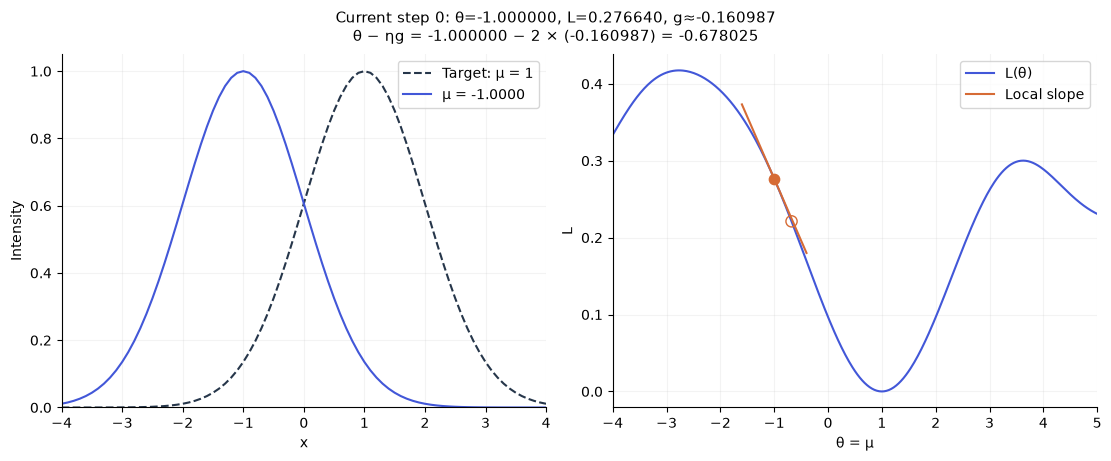

In [2]:
display(descent_figure(language=LANG))
display(descent_lab(language=LANG))

The short orange line near the current point shows the local slope of the loss. It does not replace the whole curve: far from the current center its prediction may fail. That local nature will explain what goes wrong with oversized steps.

$h$ measures the slope; $\eta$ controls the center update. They are different settings. We will first examine slope using a simple example with exact numbers, then return to the bell.

## 2. A Simple Loss: How Far a Number Is from Three

We call the adjustable parameter $\theta$, pronounced “theta.” In this small example it should approach 3. The loss will be the squared difference:

$$
L(\theta)=(\theta-3)^2.
$$

The parentheses after $L$ indicate the input: which parameter value is being evaluated. Inside the larger parentheses, we subtract 3 and then multiply the difference by itself. At $\theta=1$, we get $(1-3)^2=(-2)^2=4$. At 2 we get 1, at 3 we get 0, and at 4 we get 1 again. The graph is a bowl with its bottom at 3.

theta = 0, loss = 9
theta = 1, loss = 4
theta = 2, loss = 1
theta = 3, loss = 0
theta = 4, loss = 1
theta = 5, loss = 4


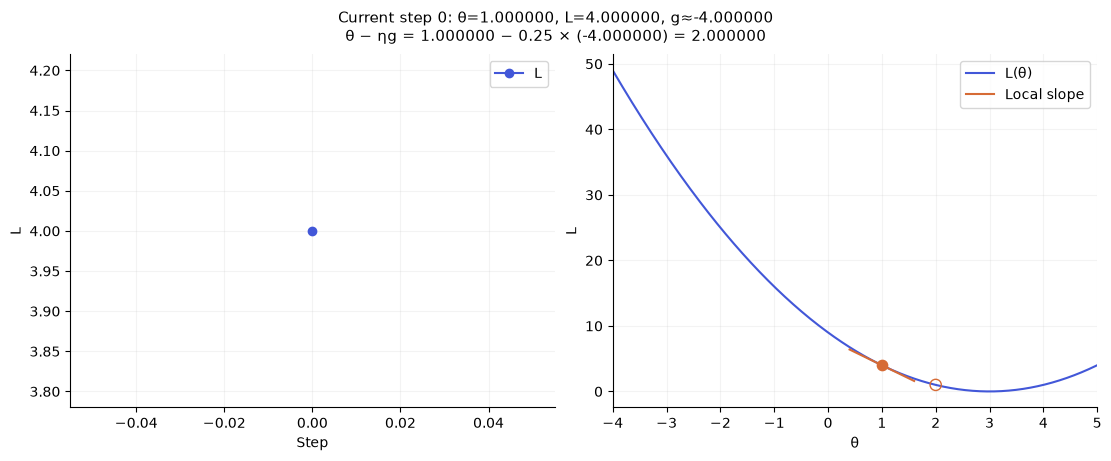

In [3]:
def toy_loss(theta):
    return (theta - 3) ** 2

for theta in [0, 1, 2, 3, 4, 5]:
    print(f"theta = {theta}, loss = {toy_loss(theta)}")
display(descent_figure(initial=1, rate=0.25, steps=0,
                       model="quadratic", language=LANG))

The answer is already obvious: the parameter should equal 3. This example is not for finding an unknown solution. It lets us check the mechanism before using it with images and many parameters.

## 3. Loss Change per Unit of Parameter Change

We start at $\theta=1$ and move right by $h=0.1$. The new point is $1+0.1=1.1$. Its loss is $(1.1-3)^2=(-1.9)^2=3.61$.

The loss changed by $3.61-4=-0.39$. Dividing by the parameter change gives:

$$
\frac{L(1+0.1)-L(1)}{0.1}
=\frac{3.61-4}{0.1}
=\frac{-0.39}{0.1}=-3.9.
$$

The number −3.9 is the **average slope** across a short interval. Its minus sign says that moving right decreased the loss. Its magnitude describes how quickly: about 3.9 loss units per parameter unit across this interval.

This is not a promise that a large move of 1 will decrease loss by exactly 3.9. The slope changes along the way. The fraction measured one particular short interval of length 0.1.

As we reduce $h$, the numbers change like this:

| h | New loss L(1+h) | Loss change | Change / h |
|---:|---:|---:|---:|
| 1 | 1 | −3 | −3 |
| 0.5 | 2.25 | −1.75 | −3.5 |
| 0.1 | 3.61 | −0.39 | −3.9 |
| 0.01 | 3.9601 | −0.0399 | −3.99 |
| 0.001 | 3.996001 | −0.003999 | −3.999 |

The slope approaches −4. This is the derivative at 1.

## 4. The Derivative, Without Skipping the Transition

A common notation for the derivative is:

$$
L'(\theta)=\lim_{h\to0}\frac{L(\theta+h)-L(\theta)}{h}.
$$

The prime in $L'$ means derivative, not the next moment in time. $h\to0$ reads “h tends to zero”: we consider smaller and smaller nonzero displacements. $\lim$ is the value approached by the fraction. **Substituting $h=0$ into the fraction is invalid**, because it would divide zero by zero.

The numerator is a difference of two losses. The denominator is the parameter displacement. We ask which slope they approach as the interval near the current point becomes very short. Some functions do not have one unique slope at a particular point; an absolute-value example will appear below.

For our bowl, expanding the operations gives an exact answer. We temporarily write $d=\theta-3$ to shorten the notation. Then:

$$
\begin{aligned}
(d+h)^2&=(d+h)(d+h)\\
&=d^2+dh+hd+h^2\\
&=d^2+2dh+h^2.
\end{aligned}
$$

Every term in the first parentheses multiplies every term in the second. The terms $dh$ and $hd$ are equal, so together they give $2dh$. Subtracting the old loss $d^2$ gives:

$$
\frac{(d+h)^2-d^2}{h}
=\frac{2dh+h^2}{h}=2d+h,\qquad h\ne0.
$$

Both terms in the numerator contain a factor of $h$. Canceling it leaves $2d+h$. As $h$ approaches zero, $2d$ remains. Substituting $d=\theta-3$ back into the result gives:

$$
L'(\theta)=2(\theta-3).
$$

At 1, this is $2(1-3)=-4$; at 2 it is −2, at 3 it is 0, and at 4 it is 2. Left of the bottom, moving right helps; right of it, moving left helps. At the bottom the instantaneous slope is zero, even though a finite move in either direction increases the loss.

## 5. A Numerical Slope from Two Trial Images

For a complex image, we will not yet derive the derivative of every operation. Python can already compute the loss. It is enough to call that function twice with slightly different parameters.

A more symmetric estimate uses one point on the left and one on the right:

$$
g_h(\theta)=\frac{L(\theta+h)-L(\theta-h)}{2h}.
$$

$g_h$ is a derivative estimate obtained with a particular $h$. The distance between the points is not $h$ but $2h$: from $\theta-h$ to $\theta$, then another $h$ to the right. That explains the denominator. The subtraction order follows movement from left to right.

For the bowl at $\theta=1$, $h=0.1$, the left loss is $L(0.9)=(-2.1)^2=4.41$ and the right loss is $L(1.1)=3.61$. We get $(3.61-4.41)/0.2=-0.8/0.2=-4$. For this quadratic example, the symmetric estimate is exact for any nonzero $h$ in exact arithmetic. For a general curve, it is an approximation.

In [4]:
def slope(function, theta, h=0.01):
    right = function(theta + h)
    left = function(theta - h)
    return (right - left) / (2 * h)

for h in [0.5, 0.1, 0.01, 0.001]:
    print(f"h={h:g}, quadratic slope={slope(toy_loss, 1, h):.9f}")

h=0.5, quadratic slope=-4.000000000
h=0.1, quadratic slope=-4.000000000
h=0.01, quadratic slope=-4.000000000
h=0.001, quadratic slope=-4.000000000


An overly large $h$ averages the slope across too wide an interval. An extremely small one subtracts nearly identical machine numbers: rounding can swallow the difference. Smaller therefore does not always mean more accurate. A useful check compares several reasonable $h$ values rather than trusting one choice.

## 6. Back to the Gaussian Center

Now $\theta$ is the center $\mu$. An image parameter and a pixel coordinate are different quantities. For each fixed $x_i$, our bell's intensity is:

$$
P_i(\mu)=\exp\left(-\frac{(x_i-\mu)^2}{2}\right).
$$

This is the lesson 2 formula with scale $\sigma=1$: the denominator $2\sigma^2$ becomes 2. We subtract the center from the coordinate, square the difference, divide by 2, negate it, and evaluate the exponential. Height 1 and scale 1 stay fixed. The target $T_i$ is calculated the same way, but its center is 1.

We compare all 81 values:

$$
L(\mu)=\frac1{81}\sum_{i=1}^{81}\bigl(P_i(\mu)-T_i\bigr)^2.
$$

For a given center, we first build the entire curve, subtract the target, square the residuals, and average. Moving the center rebuilds **all** $P_i$, not just one pixel.

In [5]:
x = np.linspace(-4, 4, 81)
target = np.exp(-0.5 * (x - 1.0) ** 2)

def image_loss(mu):
    prediction = np.exp(-0.5 * (x - mu) ** 2)
    return np.mean((prediction - target) ** 2)

mu, h = -1.0, 0.01
left, right = image_loss(mu - h), image_loss(mu + h)
gradient = (right - left) / (2 * h)
print(f"L({mu-h:.2f}) = {left:.9f}")
print(f"L({mu+h:.2f}) = {right:.9f}")
print(f"gradient ≈ {gradient:.9f}")

L(-1.01) = 0.278245476
L(-0.99) = 0.275025729
gradient ≈ -0.160987390


The values are $L(-1.01)\approx0.278245476$ and $L(-0.99)\approx0.275025729$. Subtracting gives about −0.003219748; dividing by 0.02 gives about −0.160987390. The slope is negative: a small increase in the center reduces loss. This number is not the new center coordinate. It is only the slope so far.

## 7. One Step Down the Loss

The parameter update takes this form:

$$
\theta_{\mathrm{new}}=\theta_{\mathrm{old}}-\eta g.
$$

`old` and `new` label the previous and updated values. $g$ is the derivative, or its estimate, at the **old** point. $\eta$, pronounced “eta,” is a positive learning rate. It turns the slope magnitude into a displacement magnitude. We multiply $\eta g$ before subtracting.

If $g$ is positive, subtraction moves the parameter left. If it is negative, we subtract a negative number and the parameter increases. In either case we move against the direction of increasing loss. This is gradient descent, with just one parameter for now.

For the bowl at $\theta=1$, $g=-4$, $\eta=0.25$:

$$
\theta_{\mathrm{new}}=1-0.25\cdot(-4)=1-(-1)=2.
$$

Loss falls from 4 to $(2-3)^2=1$. The derivative is now −2, not −4. The next step is therefore $2-0.25(-2)=2.5$. The slope must be recomputed after each update.

For our bell at center −1 with $\eta=2$:

$$
\mu_{\mathrm{new}}=-1-2\cdot(-0.160987390)
\approx-1+0.321974781=-0.678025219.
$$

Loss decreases from 0.276639631 to approximately 0.221169006. The value of $\eta$ is different because the slope scale of this function is different too. There is no single good number for every problem.

In [6]:
mu, rate = -1.0, 2.0
for step in range(6):
    loss = image_loss(mu)
    print(f"step {step}: mu={mu:.6f}, MSE={loss:.9f}")
    if step < 5:
        gradient = slope(image_loss, mu, h=0.01)
        mu = mu - rate * gradient

step 0: mu=-1.000000, MSE=0.276639631
step 1: mu=-0.678025, MSE=0.221169006
step 2: mu=-0.314787, MSE=0.153566610
step 3: mu=0.058703, MSE=0.086954529
step 4: mu=0.388796, MSE=0.039020754
step 5: mu=0.632426, MSE=0.014534806


$h$ in this code is 0.01, but the actual first center displacement is about 0.322. $h$ is the distance used for two measurements; $\eta g$ is the training displacement. They cannot substitute for one another.

## 8. Small, Large, and Excessive Steps

The simple bowl makes different rates easy to check. Starting from 1:

| η | New parameter | New loss | What happened |
|---:|---:|---:|---|
| 0.1 | 1 − 0.1(−4) = 1.4 | 2.56 | Slow approach |
| 0.5 | 1 − 0.5(−4) = 3 | 0 | The bottom in one step |
| 0.9 | 1 − 0.9(−4) = 4.6 | 2.56 | Overshoot, but loss decreased |
| 1 | 1 − 1(−4) = 5 | 4 | Alternation between 1 and 5 |
| 1.1 | 1 − 1.1(−4) = 5.4 | 5.76 | Overshoot with increasing loss |

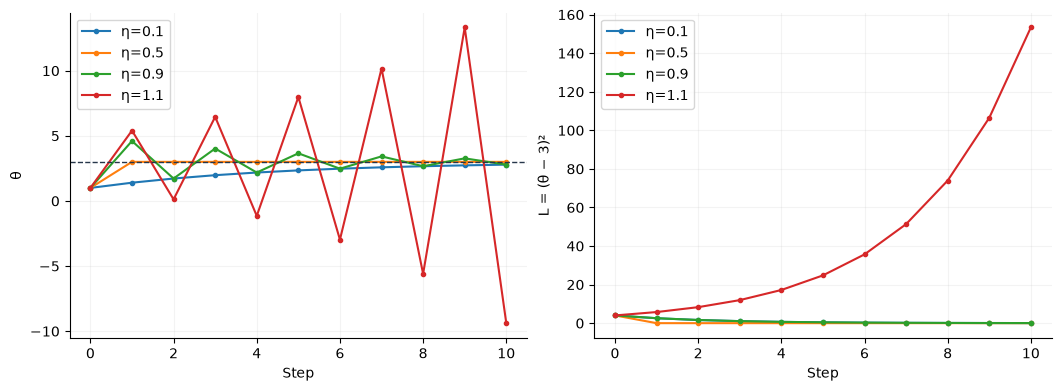

In [7]:
display(rates_figure(language=LANG))

At $\eta=0.9$, the steps cross the bottom but their amplitude shrinks. At 1.1 it grows. The derivative did not give the wrong direction: the large step simply left the region where the local slope was a useful prediction.

These particular boundaries apply to $L=(\theta-3)^2$. Multiplying loss by 100 also multiplies its derivative by 100, so the previous learning rate no longer produces the same displacement. For a complex task, the loss curve and actual update magnitudes are more informative than one “standard” rate.

## 9. Several Parameters: Each Is Changed Separately

Now the spot can change its center $\mu$ and height $a$. Loss depends on two numbers: $L(\mu,a)$. To measure the center's influence, we slightly change **only the center**, leaving height fixed. Then we restore the center and measure the height's influence. We collect the two derivatives in a list:

$$
\nabla L=
\begin{bmatrix}
\partial L/\partial\mu\\
\partial L/\partial a
\end{bmatrix}
=\begin{bmatrix}g_\mu\\g_a\end{bmatrix}.
$$

$\nabla$, called “nabla,” denotes the **gradient**: the collection of derivatives with respect to all parameters. The rounded $\partial$ is the partial-derivative symbol: one selected parameter changes while the others remain fixed. It does not mean dividing loss by the center. The vector here is a column of two numbers in the same order as the parameters.

To keep the arithmetic visible, we temporarily use this loss:

$$
Q(\mu,a)=(\mu-1)^2+4(a-0.5)^2.
$$

The first term compares the center to 1; the second compares height to 0.5. The factor 4 makes the second squared residual four times as influential. Using the square rule already derived, $g_\mu=2(\mu-1)$ and $g_a=4\cdot2(a-0.5)=8(a-0.5)$. At $(\mu,a)=(0,1)$, the gradient is $(-2,4)$.

A step with $\eta=0.1$ updates both numbers from **the same old state**:

$$
\mu_{\mathrm{new}}=0-0.1(-2)=0.2,\qquad
a_{\mathrm{new}}=1-0.1\cdot4=0.6.
$$

Old loss is $1+4\cdot0.25=2$. New loss is $(-0.8)^2+4(0.1)^2=0.64+0.04=0.68$. That is the entire vector operation: two ordinary multiplications and two subtractions.

For the real bell, we compute both derivatives numerically:

gradient: [-0.0965959   0.10158385]
updated: [-0.8068082   0.39683231]
loss before / after: 0.20099493558592782 0.17649271711783351


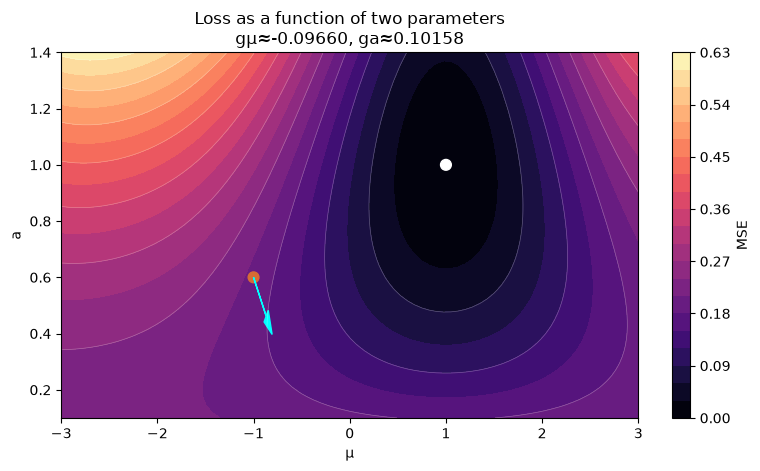

In [8]:
parameters = np.array([-1.0, 0.6])  # center, height

def two_parameter_loss(values):
    mu, gain = values
    prediction = gain * np.exp(-0.5 * (x - mu) ** 2)
    return np.mean((prediction - target) ** 2)

gradient = numerical_gradient(two_parameter_loss, parameters, h=0.001)
updated = parameters - 2.0 * gradient
print("gradient:", gradient)
print("updated:", updated)
print("loss before / after:", two_parameter_loss(parameters), two_parameter_loss(updated))
display(gradient_figure(language=LANG))

On the map, the horizontal axis is center and the vertical axis is height. Color shows MSE for each parameter pair, with darker regions indicating lower loss. The orange point is the initial pair (−1, 0.6); the white point is the exact match (1, 1). The cyan arrow shows one update with rate 2 against the gradient. To show the shape of the loss, the height axis extends to 1.4. This is a mathematical extension of the function without clipping values, rather than a bounded display-intensity scale. The project will specify valid color ranges separately.

At center −1 and height 0.6, we get approximately $g_\mu=-0.096596$ and $g_a=0.101584$. The center moves right and height decreases, even though the target height is 1! While the spot is in the wrong place, weakening it also helps by removing some incorrect brightness. The gradient answers a local question about total loss. It does not independently recognize the “correct value” of each parameter.

The numerical magnitudes of these components depend on parameter units. Converting a coordinate from meters to centimeters changes its derivative. Comparing magnitudes and assigning the same rate to center, color, and scale without considering their ranges can be awkward. The project will give parameters explicit ranges and the update method its own settings.

## 10. Zero Slope Does Not Always Mean a Solution

Our bowl's zero derivative occurs at its bottom. But for $-(\theta-3)^2$, the same point would be a **maximum**. Nearly flat regions can also occur far from a good solution. A small gradient is not enough; the loss and image remain part of the check.

The bell also introduces the image boundary. Starting at center 4 places much of the spot near the right edge. The local loss slope is negative: a small move **even farther right** reduces MSE, although the target center is 1. The program removes the misplaced spot from the visible region instead of immediately moving it onto the target. Beyond the frame, a nonzero error from the missing target remains, but the center can barely affect it.

In [9]:
for mu in [1.0, 4.0, 4.1, 8.0]:
    print(f"mu={mu:g}: MSE={image_loss(mu):.6f}, slope≈{slope(image_loss, mu):.6f}")

mu=1: MSE=0.000000, slope≈-0.000000
mu=4: MSE=0.288928, slope≈-0.053858
mu=4.1: MSE=0.283123, slope≈-0.061723
mu=8: MSE=0.218819, slope≈0.000002


This is not a sign error in the code. The derivative is locally correct, but the whole problem need not be one convenient bowl. Initial positions, scales, and image coverage affect training. We will return to them in the project.

There can also be a function with no derivative at a particular point: $|\theta|$ has slope −1 left of zero and +1 right of zero. At zero they do not approach one common value. A symmetric difference returns 0, but that does not prove the derivative exists. Libraries choose conventions at such points. We started with smooth MSE and a smooth Gaussian to understand the main mechanism first.

## 11. Experiments with Predictions

**The other sign.** For the bowl $L=(\theta-3)^2$, the old parameter is 5 and the learning rate is 0.25. Where does it move, and what is the new loss?

<details>
<summary>Worked answer</summary>

The derivative is $2(5-3)=4$, positive. The update is $5-0.25\cdot4=4$. Loss was 4 and becomes 1. A positive slope decreases the parameter rather than increasing it.

</details>

**The measurement changed, not the training rate.** In the bell experiment, $h$ decreases from 0.1 to 0.01 while $\eta=2$ stays fixed. Does the training displacement shrink tenfold?

<details>
<summary>Worked answer</summary>

No. At center −1 the slope estimates are approximately −0.160854 and −0.160987. Both give an actual displacement near $2\cdot0.161=0.322$. The measurement accuracy changes, not the selected training coefficient.

</details>

**Two simultaneous updates.** For $Q$ above, the starting point is $(0,1)$ and the learning rate is 0.25. What happens?

<details>
<summary>Worked answer</summary>

The old gradient is $(-2,4)$. The new pair is $(0-0.25(-2),\ 1-0.25\cdot4)=(0.5,0)$. Loss is $(-0.5)^2+4(-0.5)^2=0.25+1=1.25$, below the original 2. But height crossed past 0.5. Repeating with the same rate makes its error oscillate: one learning rate can behave differently along different directions.

</details>

**A stationary spot outside the frame.** An almost-zero slope at center 8 comes with nonzero MSE. Does this indicate an exact reconstruction?

<details>
<summary>Worked answer</summary>

No. Our Gaussian has almost disappeared from the visible grid while the target is still missing. A small movement of the distant center barely changes observed pixels, so the derivative is small. A good stopping criterion must consider the result as well as the gradient.

</details>

Numerical differences gave us a working descent method, but each gradient component required building the image twice. A thousand parameters would already need two thousand renders for one update. In the [next lesson](lesson-08.ipynb), we will obtain derivatives through the computation chain itself and check automatic differentiation using the same small displacements.